<a href="https://colab.research.google.com/github/mfaridzmaulana/KLASIFIKASI-CITRA-DENGAN-CNN/blob/main/notebooks/09_perbandingan_akhir_MFM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:

# ==========================================
# NOTEBOOK 09
# PERBANDINGAN AKHIR HOG + SVM,
# CNN BASELINE, DAN CNN IMPROVED
# KELOMPOK 3
# ==========================================

import os
import joblib
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from google.colab import drive
from skimage.feature import hog

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ==========================================
# 1. MENGHUBUNGKAN GOOGLE DRIVE
# ==========================================

drive.mount('/content/drive')

DATASET_DIR = "/content/drive/.shortcut-targets-by-id/1LoCHPgLL2xzbYllXiCpFE89B8TmW7Efs/COMPUTER VISION_TI 2026/kelompok 3/KLASIFIKASI CITRA DENGAN CNN/DATA MENTAH"

OUTPUT_DIR = os.path.dirname(DATASET_DIR)

nama_kelas = ["TAS", "BUKU GAMBAR", "LAPTOP"]

# ==========================================
# 2. MEMUAT DATASET TESTING
# ==========================================

FILE_SPLIT = os.path.join(
    OUTPUT_DIR,
    "dataset_split.npz"
)

data = np.load(FILE_SPLIT)

X_test = data["X_test"]
y_test = data["y_test"]
k_test = data["k_test"]

# Mengubah label menjadi integer jika one-hot
y_true = (
    np.argmax(y_test, axis=1)
    if len(y_test.shape) > 1
    else y_test.astype(int)
)

# Normalisasi label kondisi
k_test = np.array([
    x.decode("utf-8") if isinstance(x, bytes) else str(x)
    for x in k_test
])

print("DATASET TESTING BERHASIL DIMUAT")
print("Jumlah testing:", len(X_test))
print("Ukuran gambar:", X_test.shape)

# ==========================================
# 3. MEMUAT MODEL HOG + SVM
# ==========================================

model_hog = joblib.load(
    os.path.join(OUTPUT_DIR, "model_hog_svm.pkl")
)

print("MODEL HOG + SVM BERHASIL DIMUAT")

# ==========================================
# 4. MEMUAT MODEL CNN BASELINE
# ==========================================

model_baseline = tf.keras.models.load_model(
    os.path.join(OUTPUT_DIR, "model_cnn_baseline.keras")
)

print("MODEL CNN BASELINE BERHASIL DIMUAT")

# ==========================================
# 5. MEMUAT MODEL CNN IMPROVED
# ==========================================

model_improved = tf.keras.models.load_model(
    os.path.join(OUTPUT_DIR, "model_cnn_improved.keras")
)

print("MODEL CNN IMPROVED BERHASIL DIMUAT")

print("\nSEMUA MODEL BERHASIL DIMUAT!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATASET TESTING BERHASIL DIMUAT
Jumlah testing: 18
Ukuran gambar: (18, 128, 128, 3)
MODEL HOG + SVM BERHASIL DIMUAT
MODEL CNN BASELINE BERHASIL DIMUAT
MODEL CNN IMPROVED BERHASIL DIMUAT

SEMUA MODEL BERHASIL DIMUAT!


In [16]:

# ==========================================
# 6. PREDIKSI SEMUA METODE
# ==========================================

def ekstraksi_hog(dataset):

    fitur = []

    for gambar in dataset:

        hasil = hog(
            gambar,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
            channel_axis=-1
        )

        fitur.append(hasil)

    return np.array(fitur)


print("MENGHITUNG PREDIKSI HOG + SVM...")

X_test_hog = ekstraksi_hog(X_test)

pred_hog = model_hog.predict(X_test_hog)


print("MENGHITUNG PREDIKSI CNN BASELINE...")

prob_baseline = model_baseline.predict(
    X_test,
    verbose=0
)

pred_baseline = np.argmax(
    prob_baseline,
    axis=1
)


print("MENGHITUNG PREDIKSI CNN IMPROVED...")

prob_improved = model_improved.predict(
    X_test,
    verbose=0
)

pred_improved = np.argmax(
    prob_improved,
    axis=1
)


print("\nSEMUA PREDIKSI SELESAI!")


MENGHITUNG PREDIKSI HOG + SVM...
MENGHITUNG PREDIKSI CNN BASELINE...
MENGHITUNG PREDIKSI CNN IMPROVED...

SEMUA PREDIKSI SELESAI!


In [17]:

# ==========================================
# 7. PERBANDINGAN AKURASI TESTING
# ==========================================

hasil_model = {
    "HOG + SVM": pred_hog,
    "CNN Baseline": pred_baseline,
    "CNN Improved": pred_improved
}

ringkasan_model = []

for nama, prediksi in hasil_model.items():

    akurasi = accuracy_score(
        y_true,
        prediksi
    )

    ringkasan_model.append({
        "Metode": nama,
        "Akurasi (%)": round(akurasi * 100, 2),
        "Prediksi Benar": int(np.sum(y_true == prediksi)),
        "Prediksi Salah": int(np.sum(y_true != prediksi))
    })


df_perbandingan = pd.DataFrame(ringkasan_model)

print("TABEL PERBANDINGAN AKURASI")
display(df_perbandingan)


TABEL PERBANDINGAN AKURASI


,Metode,Akurasi (%),Prediksi Benar,Prediksi Salah
0,HOG + SVM,72.22,13,5
1,CNN Baseline,72.22,13,5
2,CNN Improved,50.00,9,9


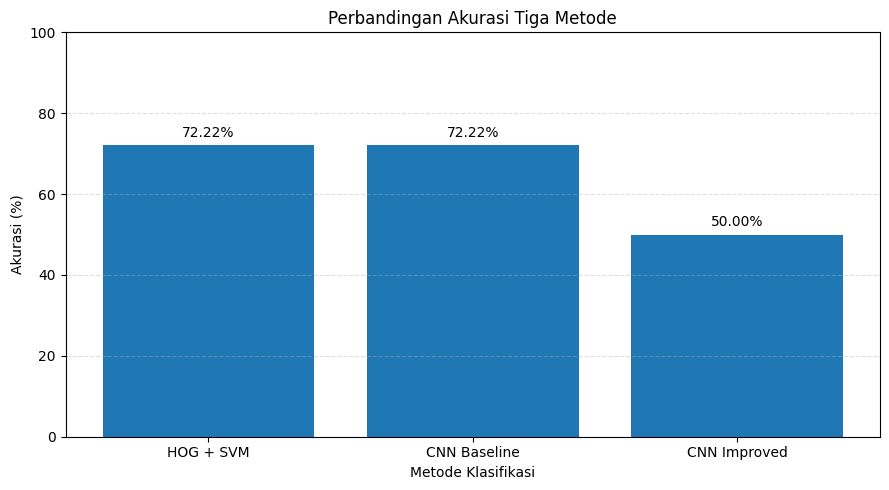

In [18]:

# ==========================================
# 8. GRAFIK PERBANDINGAN AKURASI
# ==========================================

plt.figure(figsize=(9, 5))

bars = plt.bar(
    df_perbandingan["Metode"],
    df_perbandingan["Akurasi (%)"]
)

plt.title("Perbandingan Akurasi Tiga Metode")
plt.xlabel("Metode Klasifikasi")
plt.ylabel("Akurasi (%)")
plt.ylim(0, 100)

for bar in bars:

    nilai = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        nilai + 2,
        f"{nilai:.2f}%",
        ha="center"
    )

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


PERBANDINGAN BERDASARKAN KONDISI


Kondisi,KONDISI IDEAL,KONDISI SULIT
Metode,,
CNN Baseline,66.67,77.78
CNN Improved,44.44,55.56
HOG + SVM,77.78,66.67


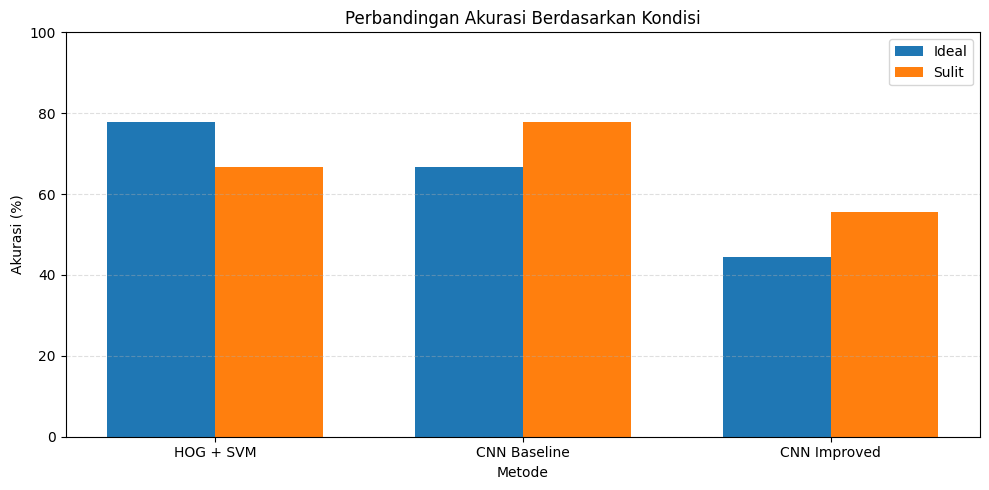

In [19]:

# ==========================================
# 9. PERBANDINGAN KONDISI IDEAL DAN SULIT
# ==========================================

hasil_kondisi_akhir = []

for nama, prediksi in hasil_model.items():

    for kondisi in ["KONDISI IDEAL", "KONDISI SULIT"]:

        indeks = np.where(k_test == kondisi)[0]

        akurasi = accuracy_score(
            y_true[indeks],
            prediksi[indeks]
        )

        hasil_kondisi_akhir.append({
            "Metode": nama,
            "Kondisi": kondisi,
            "Akurasi (%)": round(akurasi * 100, 2)
        })


df_kondisi = pd.DataFrame(hasil_kondisi_akhir)

print("PERBANDINGAN BERDASARKAN KONDISI")
display(
    df_kondisi.pivot(
        index="Metode",
        columns="Kondisi",
        values="Akurasi (%)"
    )
)

# Grafik

plt.figure(figsize=(10, 5))

x = np.arange(3)
lebar = 0.35

ideal = df_kondisi[
    df_kondisi["Kondisi"] == "KONDISI IDEAL"
]["Akurasi (%)"].values

sulit = df_kondisi[
    df_kondisi["Kondisi"] == "KONDISI SULIT"
]["Akurasi (%)"].values

plt.bar(x - lebar/2, ideal, lebar, label="Ideal")
plt.bar(x + lebar/2, sulit, lebar, label="Sulit")

plt.xticks(
    x,
    ["HOG + SVM", "CNN Baseline", "CNN Improved"]
)

plt.title("Perbandingan Akurasi Berdasarkan Kondisi")
plt.xlabel("Metode")
plt.ylabel("Akurasi (%)")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()



CONFUSION MATRIX: HOG + SVM
[[4 2 0]
 [0 6 0]
 [1 2 3]]


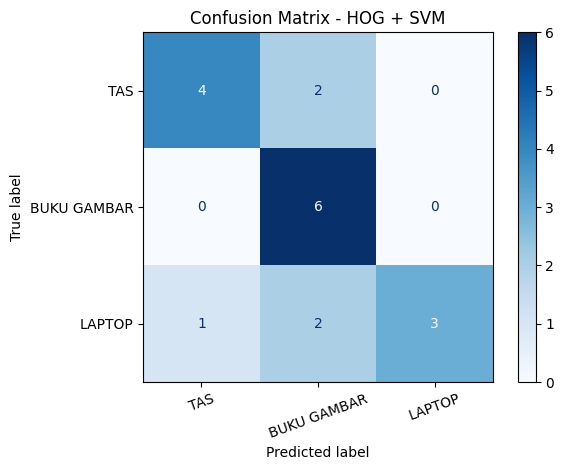


CONFUSION MATRIX: CNN Baseline
[[5 1 0]
 [0 6 0]
 [3 1 2]]


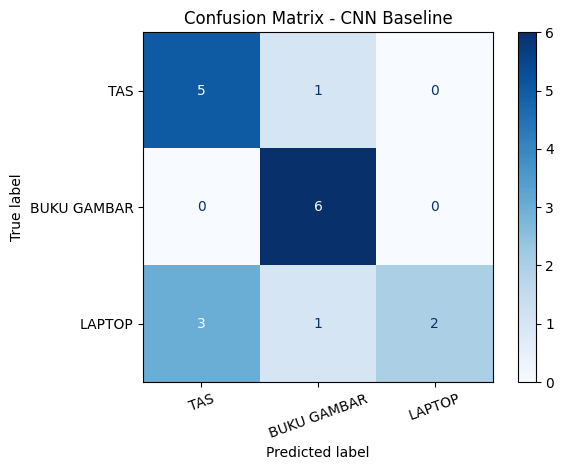


CONFUSION MATRIX: CNN Improved
[[4 2 0]
 [1 5 0]
 [4 2 0]]


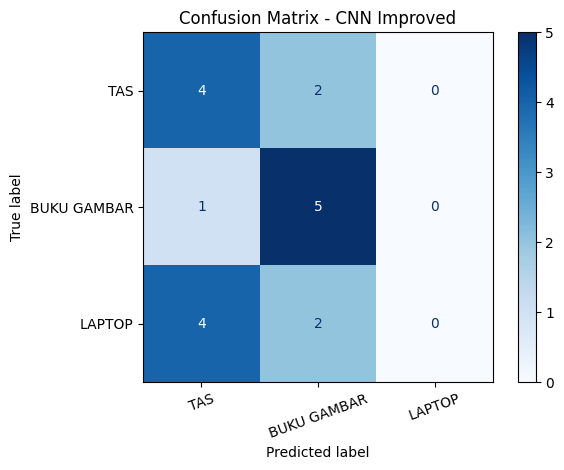

In [20]:

# ==========================================
# 10. CONFUSION MATRIX SEMUA METODE
# ==========================================

for nama, prediksi in hasil_model.items():

    cm = confusion_matrix(
        y_true,
        prediksi,
        labels=[0, 1, 2]
    )

    print("\n===================================")
    print("CONFUSION MATRIX:", nama)
    print("===================================")

    print(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=nama_kelas
    )

    disp.plot(
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"Confusion Matrix - {nama}")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()


In [21]:

# ==========================================
# 11. CLASSIFICATION REPORT
# ==========================================

for nama, prediksi in hasil_model.items():

    print("\n===================================")
    print("CLASSIFICATION REPORT:", nama)
    print("===================================")

    print(classification_report(
        y_true,
        prediksi,
        labels=[0, 1, 2],
        target_names=nama_kelas,
        zero_division=0
    ))



CLASSIFICATION REPORT: HOG + SVM
              precision    recall  f1-score   support

         TAS       0.80      0.67      0.73         6
 BUKU GAMBAR       0.60      1.00      0.75         6
      LAPTOP       1.00      0.50      0.67         6

    accuracy                           0.72        18
   macro avg       0.80      0.72      0.71        18
weighted avg       0.80      0.72      0.71        18


CLASSIFICATION REPORT: CNN Baseline
              precision    recall  f1-score   support

         TAS       0.62      0.83      0.71         6
 BUKU GAMBAR       0.75      1.00      0.86         6
      LAPTOP       1.00      0.33      0.50         6

    accuracy                           0.72        18
   macro avg       0.79      0.72      0.69        18
weighted avg       0.79      0.72      0.69        18


CLASSIFICATION REPORT: CNN Improved
              precision    recall  f1-score   support

         TAS       0.44      0.67      0.53         6
 BUKU GAMBAR       0.